In [41]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("exoplanet_data.csv", comment="#")
df.head()

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,7 CMa c,7 CMa,0,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2024-09-13,2024-07,2024-09-13
1,7 CMa c,7 CMa,1,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2019-10-18,2019-11,2019-10-24
2,DMPP-1 b,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05
3,DMPP-1 b,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
4,DMPP-1 c,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30


In [42]:
# 5 rows ad 92 colums, shape is a rectagle
print(df.columns)
# sy_loggerr1, sy_kmag, st_raderr2, pl_bmasse, soltype

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

In [43]:
dis_methods = df["discoverymethod"].value_counts()
print(dis_methods)
#7 methods
#405 transit, 121 RV, 61 ML, 6 imaging, 3 TTV, 2 ETV, 1DK, transit has most disk kiemaatics has least
#Transit: Measuring the dimming of a star when a planet passes directly in front of it.
#Radial Velocity: Detecting a star's gravitational "wobble" as an orbiting planet pulls on it.
#Microlensing: Using a star's gravity as a magnifying glass to spot a planet passing in front of a background light source.
#Direct Imaging: Taking an actual photograph of a planet by blocking out the blinding light of its host star.
#Transit Timing Variations (TTV): Finding hidden planets by noticing small delays or early arrivals in a known planet's transits.
#Eclipse Timing Variations: Detecting planets by measuring slight shifts in the timing of stellar eclipses.
#Disk Kinematics: Spotting planets by looking for physical gaps or ripples in the gas and dust disks around young stars.

discoverymethod
Transit                      405
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64


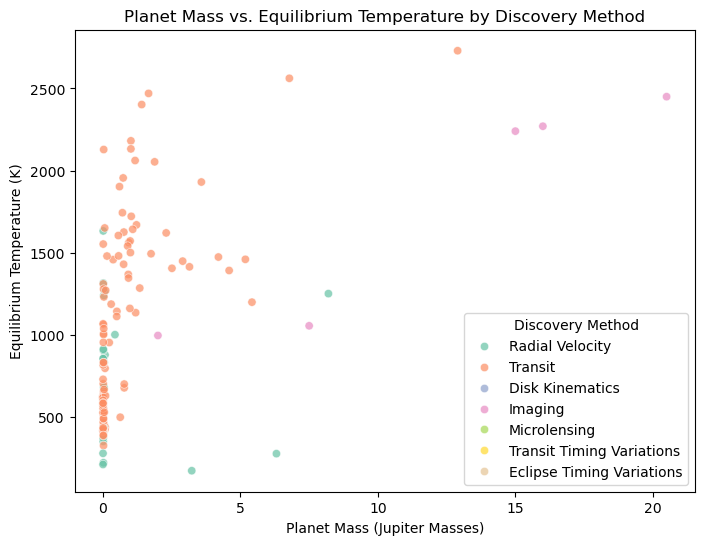

In [44]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x="pl_bmassj", y="pl_eqt", hue="discoverymethod", palette="Set2", alpha=0.7,)

plt.title("Planet Mass vs. Equilibrium Temperature by Discovery Method")
plt.xlabel("Planet Mass (Jupiter Masses)")
plt.ylabel("Equilibrium Temperature (K)")
plt.legend(title="Discovery Method")

plt.show()

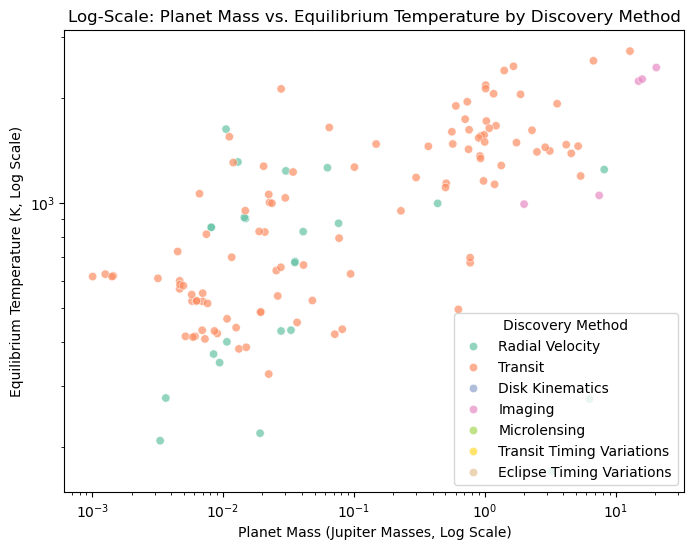

In [45]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x="pl_bmassj", y="pl_eqt", hue="discoverymethod", palette="Set2", alpha=0.7,)

plt.xscale("log")
plt.yscale("log")

plt.title("Log-Scale: Planet Mass vs. Equilibrium Temperature by Discovery Method")
plt.xlabel("Planet Mass (Jupiter Masses, Log Scale)")
plt.ylabel("Equilibrium Temperature (K, Log Scale)")
plt.legend(title="Discovery Method")

plt.show()


In [46]:
#Exoplanets found by the imaging method are more likely to be massive
df[df['pl_bmassj'] > 5].nsmallest(1, 'pl_eqt')['pl_name'].values[0]
#'eps Ind A b'

'eps Ind A b'

In [47]:
planet_row = df[df["pl_name"] == "eps Ind A b"]

print(planet_row)

print("Name:", planet_row["pl_name"].values[0])
print("Index:", planet_row.index[0])
print("Equilibrium Temperature (K):", planet_row["pl_eqt"].values[0])
print("Mass (Jupiter Masses):", planet_row["pl_bmassj"].values[0])
print("Host Star Spectral Type:", planet_row["st_spectype"].values[0])

#eps Ind A b
# 595
#Equilibrium Temperature (K): nan
#Mass (Jupiter Masses): 3.25
#Host Star Spectral Type: K2 V

         pl_name   hostname  default_flag  sy_snum  sy_pnum  discoverymethod  \
595  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   
596  eps Ind A b  eps Ind A             1        3        1  Radial Velocity   
597  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   
598  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   

     disc_year         disc_facility              soltype  pl_controv_flag  \
595       2019  La Silla Observatory  Published Confirmed                0   
596       2019  La Silla Observatory  Published Confirmed                0   
597       2019  La Silla Observatory  Published Confirmed                0   
598       2019  La Silla Observatory  Published Confirmed                0   

     ... sy_vmagerr2  sy_kmag  sy_kmagerr1  sy_kmagerr2  sy_gaiamag  \
595  ...       -0.03    2.237         0.24        -0.24     4.34562   
596  ...       -0.03    2.237         0.24        -0.24     4.3456

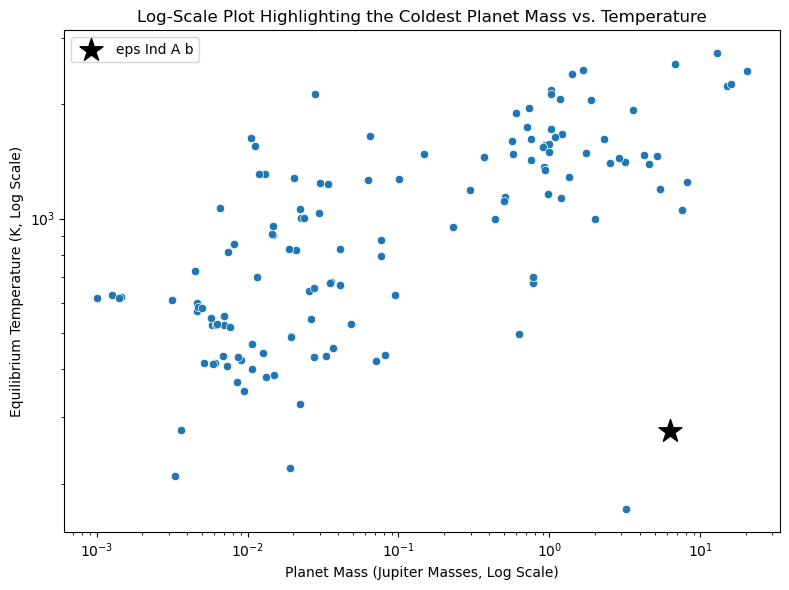

In [48]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df, x="pl_bmassj", y="pl_eqt")

coldest_planet = df[df["pl_name"] == "eps Ind A b"]

plt.scatter(coldest_planet["pl_bmassj"],coldest_planet["pl_eqt"],color="black",marker="*", s=300, label="eps Ind A b",
)

plt.xscale("log")
plt.yscale("log")

plt.title("Log-Scale Plot Highlighting the Coldest Planet Mass vs. Temperature")

plt.xlabel("Planet Mass (Jupiter Masses, Log Scale)")
plt.ylabel("Equilibrium Temperature (K, Log Scale)")
plt.legend()

plt.tight_layout()
plt.show()

In [49]:
#The 2024 Nature paper titled "A temperate super-Jupiter imaged with JWST in the mid-infrared" reports the direct imaging of a cold, massive gas giant ('eps Ind A b') whose published mass and equilibrium temperature closely match the values retrieved from the dataset.